# Assignment 1: Matplotlib
Sales dashboard built on a synthetic, seeded dataset (reproducible).

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
months  = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
monthly = np.array([42,38,45,51,58,62,60,66,71,78,95,88]) * 1000 + rng.integers(-2000, 2000, 12)
regions = ["North","South","East","West","Central"]
region_sales = np.array([310,255,280,210,150]) * 1000
categories = ["Electronics","Clothing","Home","Grocery","Other"]
cat_share  = [34, 24, 18, 16, 8]
orders = rng.gamma(shape=2.5, scale=60, size=1000)   # order values

PALETTE = ["#1F4E79","#2E86AB","#7FB3D5","#A9B7C6","#E07A5F"]
print(pd.DataFrame({"Month":months,"Sales":monthly}).T.to_string(header=False))

Month    Jan    Feb    Mar    Apr    May    Jun    Jul    Aug    Sep    Oct    Nov    Dec
Sales  40357  39095  45618  50755  57732  63434  58343  66789  69805  76376  95105  89902


## Tasks 1–3: 2×2 dashboard, styling, annotation
Line (monthly sales), bar (region), pie (category share), histogram (order values). Peak month is found programmatically and marked with `ax.annotate()` and a highlighted marker.

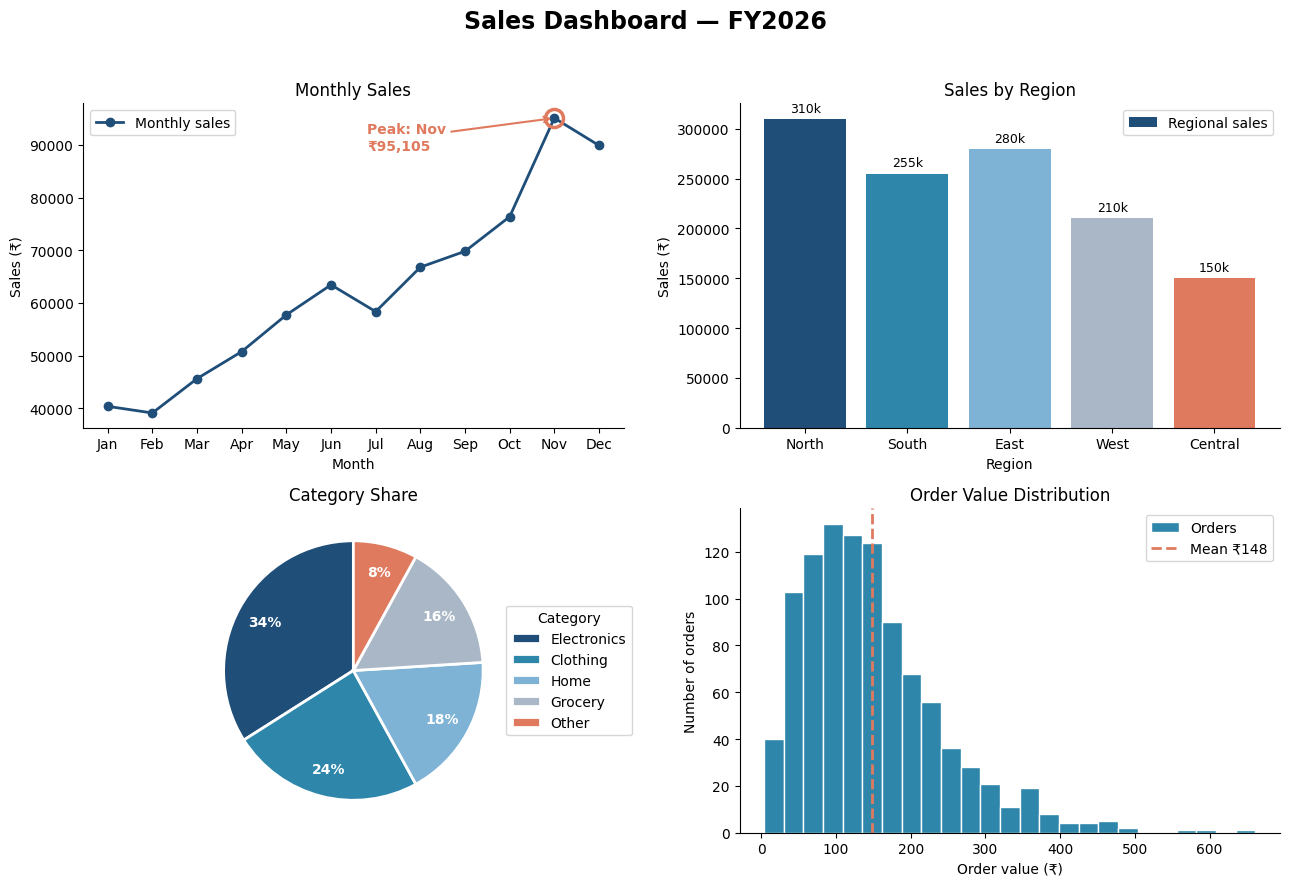

In [2]:
def build_dashboard():
    fig, axs = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle("Sales Dashboard — FY2026", fontsize=17, fontweight="bold", y=0.98)

    # 1. Line: monthly sales
    ax = axs[0, 0]
    ax.plot(months, monthly, color=PALETTE[0], marker="o", lw=2, label="Monthly sales")
    ax.set_title("Monthly Sales"); ax.set_xlabel("Month"); ax.set_ylabel("Sales (₹)")
    ax.legend(loc="upper left")

    # 3. Annotate peak month
    pk = int(np.argmax(monthly))
    ax.plot(months[pk], monthly[pk], "o", ms=13, mfc="none", mec=PALETTE[4], mew=2.5, label="Peak")
    ax.annotate(f"Peak: {months[pk]}\n₹{monthly[pk]:,}",
                xy=(pk, monthly[pk]), xytext=(pk-4.2, monthly[pk]-6000),
                arrowprops=dict(arrowstyle="->", color=PALETTE[4], lw=1.5),
                fontsize=10, color=PALETTE[4], fontweight="bold")

    # 2. Bar: sales by region
    ax = axs[0, 1]
    bars = ax.bar(regions, region_sales, color=PALETTE, label="Regional sales")
    ax.bar_label(bars, labels=[f"{v/1000:.0f}k" for v in region_sales], padding=3, fontsize=9)
    ax.set_title("Sales by Region"); ax.set_xlabel("Region"); ax.set_ylabel("Sales (₹)")
    ax.legend(loc="upper right")

    # Pie: category share
    ax = axs[1, 0]
    wedges, _, autotexts = ax.pie(cat_share, colors=PALETTE, autopct="%1.0f%%", startangle=90,
                                  wedgeprops=dict(edgecolor="white", linewidth=2), pctdistance=0.78)
    for t in autotexts: t.set_color("white"); t.set_fontweight("bold")
    ax.legend(wedges, categories, title="Category", loc="center left", bbox_to_anchor=(0.95, 0.5))
    ax.set_title("Category Share")

    # Histogram: order values
    ax = axs[1, 1]
    ax.hist(orders, bins=25, color=PALETTE[1], edgecolor="white", label="Orders")
    ax.axvline(orders.mean(), color=PALETTE[4], ls="--", lw=2, label=f"Mean ₹{orders.mean():.0f}")
    ax.set_title("Order Value Distribution"); ax.set_xlabel("Order value (₹)"); ax.set_ylabel("Number of orders")
    ax.legend()

    for a in (axs[0,0], axs[0,1], axs[1,1]):
        a.spines[["top","right"]].set_visible(False)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    return fig

fig = build_dashboard()
fig.savefig("sales_dashboard.png", dpi=200, bbox_inches="tight", facecolor="white")   # Task 2: PNG @ 200 dpi
plt.show()

## Task 4 (Bonus): Two built-in styles, same data
The same monthly-sales line chart rendered with `seaborn-v0_8-whitegrid` and `ggplot`.

['ggplot', 'seaborn-v0_8-whitegrid']


/tmp/ipykernel_178/2497505647.py:8: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Liberation Sans.
  fig.tight_layout()
/tmp/ipykernel_178/2497505647.py:9: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Liberation Sans.
  fig.savefig(fname, dpi=200, bbox_inches="tight")


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


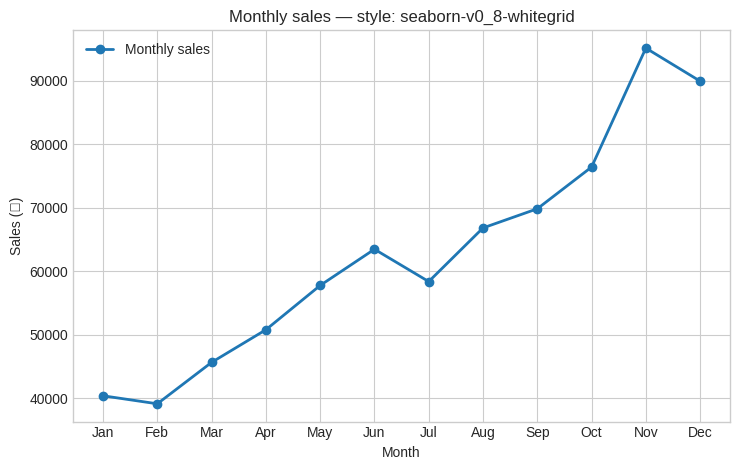

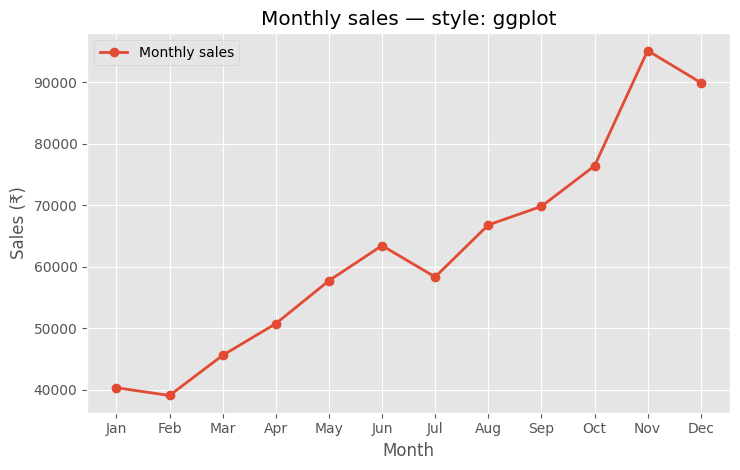

In [3]:
print([s for s in plt.style.available if s in ("seaborn-v0_8-whitegrid","ggplot")])
for style, fname in [("seaborn-v0_8-whitegrid", "style_whitegrid.png"), ("ggplot", "style_ggplot.png")]:
    with plt.style.context(style):          # create the figure INSIDE the context so the style applies to axes too
        fig, ax = plt.subplots(figsize=(7.5, 4.8))
        ax.plot(months, monthly, marker="o", lw=2, label="Monthly sales")
        ax.set_title(f"Monthly sales — style: {style}"); ax.set_xlabel("Month"); ax.set_ylabel("Sales (₹)")
        ax.legend(loc="upper left")
        fig.tight_layout()
        fig.savefig(fname, dpi=200, bbox_inches="tight")
        plt.show()

### Readability comparison
- **seaborn-v0_8-whitegrid**: white background, thin light-grey gridlines and a clean frame; the line stands out and the chart prints cleanly. Better for reports and slides.
- **ggplot**: grey panel with white gridlines and a stronger default colour. Lines read well on screen, but the grey fill lowers contrast for light series and uses more ink in print.
- **Verdict:** `seaborn-v0_8-whitegrid` is more readable for this data, mainly because of higher contrast and less visual clutter.